# Structured Extraction of Retrospective MIMIC-IV Studies: Results

This notebook produces the thesis results for **bulk structured extraction**
with retrieval-augmented generation (RAG) in the **all-papers retrieval scope**:
each of the 38 extraction questions is asked once, and the system answers with
one table row per paper.

**Unit of analysis.** One *cell* of the extraction table = one paper × one
question. The ground truth (`ML4EHR.csv`) has 12 papers × 38 questions =
456 cells, of which some are *reported* (the paper states the information) and
some are *not reported* (the correct output is "not reported").

**Systems.** Two response models are compared: **Llama 3.2 (3B)**, a
general-purpose model, and **MedLlama 2 (7B)**, a medical fine-tune of Llama 2.
Each model was run twice (V1, V2). The runs share the same retrieved contexts
but have regenerated answers, and each run was scored by a different RAGAS judge
(V1: gpt-5.6-luna, V2: ministral-8b-2512).

| Section | Question |
| --- | --- |
| 1. Dataset and extraction schema | What is extracted, and how often is it reported? |
| 2. Extraction completeness | Does every table contain every paper? How much evidence is retrieved per paper? |
| 3. Reporting-status detection | Can the system tell reported fields from not-reported ones? |
| 4. Accuracy of extracted values | How many reported cells are correct, and do failures come from retrieval or generation? |
| 5. Per-field accuracy | Which fields can be extracted reliably? |
| 6. Automated vs manual evaluation | Can RAGAS replace manual review at scale? |
| 7. Summary of key results | One table across runs and models |
| Appendix | RAGAS score summaries and RAGAS retrieval scores by field |

All figures are written to `analysis_outputs/thesis/<section>/` as PNG, SVG and PDF.

## 0. Setup and data loading

In [1]:
import ast
from pathlib import Path

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root_candidates = [
    Path.cwd(), Path.cwd() / "rag_evaluation",
    Path.cwd() / "llm4ehr" / "rag_evaluation", *Path.cwd().parents,
]
BASE_DIR = next((p for p in root_candidates if (p / "manually_reviewed").is_dir()), None)
if BASE_DIR is None:
    raise FileNotFoundError("Open this notebook from the repository or rag_evaluation directory.")
REVIEW_DIR = BASE_DIR / "manually_reviewed"
THESIS_DIR = BASE_DIR / "analysis_outputs" / "thesis"

VERSIONS = ["V1", "V2"]
MODELS = ["Llama", "MedLlama"]
MODEL_TAGS = {"Llama": "llama3.2:3b", "MedLlama": "medllama2:7b"}
MODEL_LABELS = {"Llama": "Llama 3.2 (3B)", "MedLlama": "MedLlama 2 (7B)"}
MODEL_TYPES = {"Llama": "general-purpose", "MedLlama": "medical fine-tune"}
RUN_INDEX = pd.MultiIndex.from_product([VERSIONS, MODELS], names=["version", "model"])
PAIR_KEYS = ["query_id", "category", "article_id"]
REFERENCE_KEYS = ["article_id", "category"]
EXPECTED_SCOPE = "all_papers"
CORRECTNESS_THRESHOLD = 0.75  # evaluate_rag.py --correctness-threshold used for the judge category

# Filenames differ across exports; keep the exact inputs explicit.
STATUS_FILES = {
    ("V1", "Llama"): {"reported": "llama_3_2b_V1_reported.csv", "no_reported": "llama_3_2b_V1_not_reported.csv"},
    ("V1", "MedLlama"): {"reported": "medllama_2_7b_V1_reported.csv", "no_reported": "medllama2_7b_V1_not_reported.csv"},
    ("V2", "Llama"): {"reported": "llama_3_2b_V2_reported.csv", "no_reported": "llama3_2_2b_V2_not_reported.csv"},
    ("V2", "MedLlama"): {"reported": "medllama_2_7b_V2_reported.csv", "no_reported": "medllama2_7b_V2_not_reported.csv"},
}
RAGAS_METRICS = {
    "faithfulness": "Faithfulness",
    "answer_relevancy": "Answer relevancy",
    "context_recall": "Context recall",
    "llm_context_precision_with_reference": "Context precision",
    "answer_correctness": "Answer correctness",
}
FIELD_LABELS = {
    "cohort": "Cohort", "outcome": "Outcome", "window": "Time windows",
    "features": "Features", "processing": "Processing",
    "modelling": "Modelling", "evaluation": "Evaluation",
}
# Figures are drawn at their printed size: TEXT_WIDTH is \linewidth of the thesis
# (US letter, 3 cm margins), so include them with width=\linewidth and no scaling.
TEXT_WIDTH = 6.14  # inches
PLOT_STYLE = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
    "figure.facecolor": "white", "axes.facecolor": "white",
}

def section_dir(name):
    directory = THESIS_DIR / name
    directory.mkdir(parents=True, exist_ok=True)
    return directory

def save_figure(fig, directory, stem):
    # No bbox_inches="tight": it would change the width and thus the printed font size.
    if fig.get_figwidth() > TEXT_WIDTH + 0.01:
        print(f"warning: {stem} is wider than the text ({fig.get_figwidth():.2f} in)")
    for extension in ["png", "svg", "pdf"]:
        fig.savefig(directory / f"{stem}.{extension}", dpi=600)
    plt.show()
    plt.close(fig)

def normalize_status(values, source):
    normalized = values.astype("string").str.strip().str.lower().str.replace(r"[\s_-]+", "_", regex=True)
    normalized = normalized.replace({"not_reported": "no_reported", "non_reported": "no_reported", "unreported": "no_reported"})
    if not normalized.isin(["reported", "no_reported"]).all():
        raise ValueError(f"Unknown or missing reporting status in {source}")
    return normalized

def safe_rate(numerator, denominator):
    return numerator / denominator if denominator else np.nan

def wilson_interval(successes, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def separation_auc(good, bad):
    """Mann-Whitney AUC: P(good scores higher than bad), ties count one half."""
    good, bad = np.asarray(good, dtype=float), np.asarray(bad, dtype=float)
    good, bad = good[np.isfinite(good)], bad[np.isfinite(bad)]
    if not len(good) or not len(bad):
        return np.nan
    return float(((good[:, None] > bad[None, :]) + 0.5 * (good[:, None] == bad[None, :])).mean())

In [2]:
dataset = pd.read_csv(BASE_DIR / "datasets" / "ML4EHR.csv", encoding="utf-8-sig")

# The source CSV leaves repeated paper and field metadata blank.
for column in ["article_id", "article_title", "field_id"]:
    dataset[column] = dataset[column].astype("string").str.strip().replace("", pd.NA).ffill()
for column in ["category", "question", "status"]:
    dataset[column] = dataset[column].astype("string").str.strip()
required = ["article_id", "field_id", "category", "question", "status"]
if dataset[required].isna().any().any() or dataset[required].eq("").any().any():
    raise ValueError("Missing paper, field, category, query, or status in the dataset.")
if dataset.duplicated(REFERENCE_KEYS).any():
    raise ValueError("Duplicate paper/category reference pairs in the dataset.")
dataset["status"] = normalize_status(dataset["status"], "ML4EHR.csv")
query_catalog = dataset[["category", "field_id"]].drop_duplicates()
if query_catalog["category"].duplicated().any():
    raise ValueError("A query category is assigned to more than one field.")
field_order = query_catalog["field_id"].drop_duplicates().tolist()

In [3]:
CELL_COLUMNS = PAIR_KEYS + [
    "reference_status", "response_status", "response_model", "judge_model", "retrieval_scope",
    "response_paper_count", "matched_response_paper", "extra_paper_count", "retrieved_context_count",
    "retrieved_contexts", "max_eval_context_chars",
] + list(RAGAS_METRICS)
REVIEW_COLUMNS = ["failure_category", "manual_label"]  # manual review exists for reported cells only

reference_table = dataset[REFERENCE_KEYS + ["field_id", "status"]].rename(columns={"status": "reference_status"})
expected_pairs = pd.MultiIndex.from_frame(reference_table[REFERENCE_KEYS])
frames = []
for version in VERSIONS:
    for model in MODELS:
        partitions = []
        for subset, filename in STATUS_FILES[(version, model)].items():
            path = REVIEW_DIR / f"results_{version}" / filename
            frame = pd.read_csv(path, usecols=CELL_COLUMNS + (REVIEW_COLUMNS if subset == "reported" else []))
            frame["query_id"] = pd.to_numeric(frame["query_id"], errors="raise").astype(int)
            for column in REFERENCE_KEYS + ["judge_model", "retrieval_scope"]:
                frame[column] = frame[column].astype("string").str.strip().replace("", pd.NA)
            if frame[PAIR_KEYS].isna().any().any() or frame.duplicated(REFERENCE_KEYS).any():
                raise ValueError(f"Missing or duplicate observation keys in {path.name}")
            if not frame["response_model"].eq(MODEL_TAGS[model]).all():
                raise ValueError(f"Unexpected response model in {path.name}")
            if not frame["retrieval_scope"].eq(EXPECTED_SCOPE).all():
                raise ValueError(f"Expected retrieval_scope={EXPECTED_SCOPE} in {path.name}")
            frame["reference_status"] = normalize_status(frame["reference_status"], path.name)
            frame["response_status"] = normalize_status(frame["response_status"], path.name)
            if not frame["reference_status"].eq(subset).all():
                raise ValueError(f"Reference statuses do not match the {subset} partition in {path.name}")
            frame["source_file"] = path.name
            partitions.append(frame)
        combined = pd.concat(partitions, ignore_index=True)
        actual_pairs = pd.MultiIndex.from_frame(combined[REFERENCE_KEYS])
        if len(expected_pairs.difference(actual_pairs)) or len(actual_pairs.difference(expected_pairs)):
            raise ValueError(f"Results for {version} / {model} do not cover ML4EHR.csv exactly once")
        combined = combined.rename(columns={"reference_status": "file_reference_status"}).merge(
            reference_table, on=REFERENCE_KEYS, how="left", validate="one_to_one",
        )
        if combined["file_reference_status"].ne(combined["reference_status"]).any():
            raise ValueError(f"Result reference statuses disagree with ML4EHR.csv for {version} / {model}")
        combined["version"], combined["model"] = version, model
        frames.append(combined.drop(columns="file_reference_status"))

results = pd.concat(frames, ignore_index=True)
if results["judge_model"].isna().any() or results.groupby("version")["judge_model"].nunique().ne(1).any():
    raise ValueError("Each run must have exactly one nonempty RAGAS judge.")
JUDGE_MODELS = results.groupby("version")["judge_model"].first().to_dict()
if results[["query_id", "category"]].drop_duplicates()["query_id"].duplicated().any():
    raise ValueError("Query identifiers and categories must map one-to-one.")
for metric in RAGAS_METRICS:
    results[metric] = pd.to_numeric(results[metric], errors="raise").astype(float)
    if not results[metric].dropna().between(0, 1).all():
        raise ValueError(f"RAGAS scores outside [0, 1]: {metric}")
results["matched_response_paper"] = results["matched_response_paper"].astype(str).str.lower().eq("true")
# Keep only the evaluated evidence length; the context text itself is not needed downstream.
results["evaluated_context_chars"] = results.pop("retrieved_contexts").map(
    lambda contexts: sum(len(context) for context in ast.literal_eval(contexts))
)

reported = results["reference_status"].eq("reported")
answered = results["response_status"].eq("reported")
results["status_class"] = np.select(
    [reported & answered, reported & ~answered, ~reported & answered, ~reported & ~answered],
    ["TP", "FN", "FP", "TN"],
)
query_order = results[["query_id", "category"]].drop_duplicates().sort_values("query_id")["category"].tolist()
display(Markdown(
    f"**Loaded:** {len(results):,} cells = {len(RUN_INDEX)} runs × {len(dataset)} cells "
    f"({dataset['article_id'].nunique()} papers × {len(query_catalog)} questions); "
    f"retrieval scope `{EXPECTED_SCOPE}` throughout. Judges: "
    + ", ".join(f"{version} = {judge}" for version, judge in JUDGE_MODELS.items()) + "."
))

**Loaded:** 1,824 cells = 4 runs × 456 cells (12 papers × 38 questions); retrieval scope `all_papers` throughout. Judges: V1 = gpt-5.6-luna, V2 = ministral-8b-2512.

## 1. Dataset and extraction schema

The extraction schema has 38 questions grouped into seven broad fields
(`field_id`). Reporting status is counted per cell (paper × question).

**Figure caption:** Dataset composition and reference reporting status.
(a) Numbers of papers, extraction questions, and broad fields.
(b) Reported and not-reported cells; percentages use all cells as the denominator.

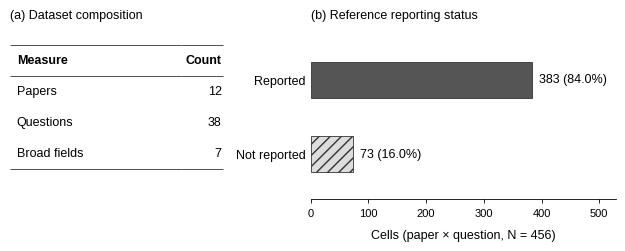

In [4]:
S1_DIR = section_dir("1_dataset")
status_counts = dataset["status"].value_counts().reindex(["reported", "no_reported"], fill_value=0)
total_cells = len(dataset)
overview = pd.Series({
    "Papers": dataset["article_id"].nunique(),
    "Questions": len(query_catalog),
    "Broad fields": len(field_order),
    "Reported cells": int(status_counts["reported"]),
    "Not-reported cells": int(status_counts["no_reported"]),
}, name="Count")
overview.to_csv(S1_DIR / "dataset_overview_counts.csv", index_label="Measure")

with plt.rc_context({**PLOT_STYLE, "font.size": 9, "ytick.labelsize": 9}):
    fig, (summary_ax, status_ax) = plt.subplots(
        1, 2, figsize=(TEXT_WIDTH, 2.4), gridspec_kw={"width_ratios": [1, 1.4]}, layout="constrained",
    )
    summary_ax.set_title("(a) Dataset composition", loc="left", pad=12)
    summary_ax.axis("off")
    table = summary_ax.table(
        cellText=[[label, f"{value:,}"] for label, value in overview.iloc[:3].items()],
        colLabels=["Measure", "Count"], colWidths=[0.80, 0.20],
        cellLoc="left", colLoc="left", bbox=[0, 0.18, 0.98, 0.76], edges="open",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    for (row, column), cell in table.get_celld().items():
        cell.PAD = 0.04
        cell.set_edgecolor("#333333")
        cell.set_linewidth(0.6)
        if column == 1:
            cell.get_text().set_ha("right")
        if row == 0:
            cell.visible_edges = "TB"
            cell.get_text().set_weight("bold")
        elif row == 3:
            cell.visible_edges = "B"

    counts = status_counts.to_numpy(dtype=int)
    bars = status_ax.barh(["Reported", "Not reported"], counts, height=0.48,
                          color=["#555555", "#dddddd"], edgecolor="#333333", linewidth=0.6)
    bars[1].set_hatch("///")
    status_ax.bar_label(bars, labels=[f"{count:,} ({count / total_cells:.1%})" for count in counts],
                        padding=5, fontsize=9)
    status_ax.set_ylim(1.6, -0.6)
    status_ax.set_xlim(0, max(counts) * 1.38)
    status_ax.set_xticks(np.arange(0, max(counts) * 1.38, 100))
    status_ax.set_title("(b) Reference reporting status", loc="left", pad=12)
    status_ax.set_xlabel(f"Cells (paper × question, N = {total_cells:,})", labelpad=8)
    status_ax.spines[["top", "right", "left"]].set_visible(False)
    status_ax.spines["bottom"].set_linewidth(0.6)
    status_ax.tick_params(axis="y", length=0)
    status_ax.tick_params(axis="x", width=0.6, length=3)
    save_figure(fig, S1_DIR, "01_dataset_overview")

**Table:** Extraction schema by broad field: number of questions, number of
cells, and the share of cells whose information is reported in the paper.

In [5]:
schema = (
    dataset.groupby("field_id", sort=False)
    .agg(questions=("category", "nunique"), cells=("category", "size"),
         reported_cells=("status", lambda status: int(status.eq("reported").sum())))
    .reindex(field_order)
)
schema["not_reported_cells"] = schema["cells"] - schema["reported_cells"]
schema["reported_share"] = schema["reported_cells"] / schema["cells"]
schema.index = schema.index.map(FIELD_LABELS)
schema.loc["Total"] = [schema["questions"].sum(), schema["cells"].sum(), schema["reported_cells"].sum(),
                       schema["not_reported_cells"].sum(), schema["reported_cells"].sum() / schema["cells"].sum()]
schema.to_csv(S1_DIR / "extraction_schema_by_field.csv")
display(schema.style.format({"reported_share": "{:.1%}", "questions": "{:.0f}", "cells": "{:.0f}",
                             "reported_cells": "{:.0f}", "not_reported_cells": "{:.0f}"}))

,questions,cells,reported_cells,not_reported_cells,reported_share
field_id,,,,,
Cohort,11,132,106,26,80.3%
Outcome,6,72,61,11,84.7%
Time windows,2,24,23,1,95.8%
Features,4,48,42,6,87.5%
Processing,4,48,43,5,89.6%
Modelling,4,48,39,9,81.2%
Evaluation,7,84,69,15,82.1%
Total,38,456,383,73,84.0%


## 2. Extraction completeness and evidence per paper

In the all-papers scope, every question must return one table row per paper.
A paper is **covered** when its row could be matched to the reference paper;
**extra** rows name papers that are not in the reference set.

**Evidence per paper.** For each question, the retriever reranks chunks within
every paper and merges the top chunks (at most two, `max_chunks_per_article=2`
in `app/rag/services/retrieval_service.py`) into one context block per paper.
The table reports the number of blocks per cell and the length of the block as
evaluated by RAGAS, which is truncated at `max_eval_context_chars`; the response
model may have seen a longer block.

In [6]:
S2_DIR = section_dir("2_completeness")
per_query = (
    results.groupby(["version", "model", "query_id"])
    .agg(expected_rows=("article_id", "size"), matched_rows=("matched_response_paper", "sum"),
         returned_rows=("response_paper_count", "max"), extra_rows=("extra_paper_count", "max"))
    .reset_index()
)
per_query["complete"] = per_query["matched_rows"].eq(per_query["expected_rows"]) & per_query["extra_rows"].eq(0)
completeness = per_query.groupby(["version", "model"]).agg(
    questions=("query_id", "nunique"), expected_rows=("expected_rows", "sum"),
    matched_rows=("matched_rows", "sum"), extra_rows=("extra_rows", "sum"),
    complete_tables=("complete", "sum"),
).reindex(RUN_INDEX)
completeness["missing_rows"] = completeness["expected_rows"] - completeness["matched_rows"]
completeness["paper_coverage"] = completeness["matched_rows"] / completeness["expected_rows"]

results["context_at_cap"] = results["evaluated_context_chars"].ge(results["max_eval_context_chars"])
evidence = results.groupby(["version", "model"]).agg(
    blocks_min=("retrieved_context_count", "min"), blocks_max=("retrieved_context_count", "max"),
    chars_median=("evaluated_context_chars", "median"), chars_min=("evaluated_context_chars", "min"),
    chars_max=("evaluated_context_chars", "max"), char_cap=("max_eval_context_chars", "max"),
    share_at_cap=("context_at_cap", "mean"),
).reindex(RUN_INDEX)
completeness = completeness.join(evidence)
completeness.to_csv(S2_DIR / "completeness_and_evidence.csv")
per_query.to_csv(S2_DIR / "completeness_per_question.csv", index=False)
display(completeness.round(3))
display(Markdown(
    f"**Completeness:** {int(completeness['complete_tables'].sum())} of {int(completeness['questions'].sum())} "
    f"answer tables across all runs contain every reference paper and no extra paper "
    f"(paper coverage {completeness['paper_coverage'].min():.1%}–{completeness['paper_coverage'].max():.1%}). "
    f"**Evidence per paper:** {int(evidence['blocks_min'].min())}–{int(evidence['blocks_max'].max())} context block "
    f"per cell; median evaluated length {evidence['chars_median'].median():,.0f} characters, with "
    f"{evidence['share_at_cap'].mean():.1%} of blocks truncated at the {int(evidence['char_cap'].max()):,}-character "
    "evaluation cap."
))

questions  expected_rows  matched_rows  extra_rows  \
version model                                                          
V1      Llama            38            456           456           0   
        MedLlama         38            456           456           0   
V2      Llama            38            456           456           0   
        MedLlama         38            456           456           0   

                  complete_tables  missing_rows  paper_coverage  blocks_min  \
version model                                                                 
V1      Llama                  38             0             1.0           1   
        MedLlama               38             0             1.0           1   
V2      Llama                  38             0             1.0           1   
        MedLlama               38             0             1.0           1   

                  blocks_max  chars_median  chars_min  chars_max  char_cap  \
version model                                                                
V1      Llama              1        2259.0       1131       2500      2500   
        MedLlama           1        2259.0       1131       2500      2500   
V2      Llama              1        2259.0       1131       2500      2500   
        MedLlama           1        2259.0       1131       2500      2500   

                  share_at_cap  
version model                   
V1      Llama            0.195  
        MedLlama         0.195  
V2      Llama            0.195  
        MedLlama         0.195

**Completeness:** 152 of 152 answer tables across all runs contain every reference paper and no extra paper (paper coverage 100.0%–100.0%). **Evidence per paper:** 1–1 context block per cell; median evaluated length 2,259 characters, with 19.5% of blocks truncated at the 2,500-character evaluation cap.

## 3. Reporting-status detection

A structured extraction must leave a cell empty when the paper does not report
the information. The response status (reported / not reported) is inferred
from each table cell by rule (`infer_response_status` in `evaluate_rag.py`) and
does not depend on the RAGAS judge.

Reported is the positive class: **TP** = reported/reported,
**FN** = reported/not reported, **FP** = not reported/reported (a value
extracted for an unreported field), **TN** = not reported/not reported.

**Figure caption:** Reporting-status confusion matrices for each response model
and run (456 cells each). Rows denote reference status and columns response
status; cells show counts and row percentages on a common 0–100% grayscale.

status_class       TP   FN  FP  TN  sensitivity  specificity  \
version model                                                  
V1      Llama     281  102  11  62        0.734        0.849   
        MedLlama  331   52  23  50        0.864        0.685   
V2      Llama     293   90   9  64        0.765        0.877   
        MedLlama  336   47  27  46        0.877        0.630   

status_class      precision_reported  precision_not_reported  \
version model                                                  
V1      Llama                  0.962                   0.378   
        MedLlama               0.935                   0.490   
V2      Llama                  0.970                   0.416   
        MedLlama               0.926                   0.495   

status_class      balanced_accuracy  
version model                        
V1      Llama                 0.791  
        MedLlama              0.775  
V2      Llama                 0.821  
        MedLlama              0.754

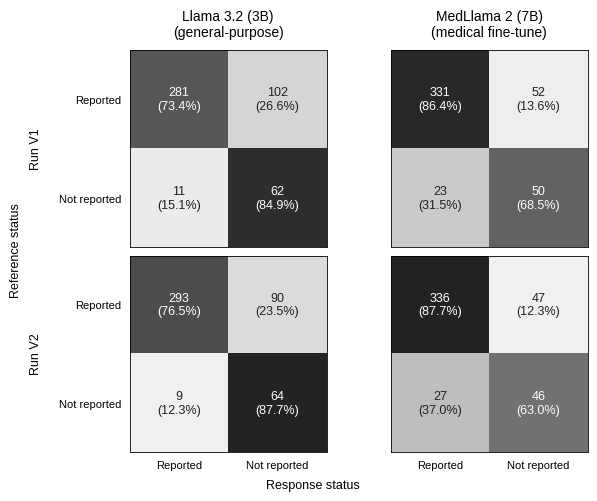

In [7]:
S3_DIR = section_dir("3_status_detection")
OUTCOMES = ["TP", "FN", "FP", "TN"]
status_counts_by_run = (
    results.groupby(["version", "model", "status_class"]).size()
    .unstack(fill_value=0).reindex(index=RUN_INDEX, columns=OUTCOMES, fill_value=0)
)
status_metrics = status_counts_by_run.copy()
status_metrics["sensitivity"] = status_counts_by_run.eval("TP / (TP + FN)")
status_metrics["specificity"] = status_counts_by_run.eval("TN / (TN + FP)")
status_metrics["precision_reported"] = status_counts_by_run.eval("TP / (TP + FP)")
status_metrics["precision_not_reported"] = status_counts_by_run.eval("TN / (TN + FN)")
status_metrics["balanced_accuracy"] = (status_metrics["sensitivity"] + status_metrics["specificity"]) / 2
status_metrics.to_csv(S3_DIR / "status_detection_metrics.csv")
status_by_field = (
    results.groupby(["version", "model", "field_id", "status_class"]).size()
    .unstack(fill_value=0).reindex(columns=OUTCOMES, fill_value=0)
)
status_by_field.to_csv(S3_DIR / "status_by_field.csv")
display(status_metrics.round(3))

with plt.rc_context({**PLOT_STYLE, "axes.titlesize": 10}):
    fig, axes = plt.subplots(2, 2, figsize=(TEXT_WIDTH, 4.9), sharex=True, sharey=True, layout="constrained")
    for row, version in enumerate(VERSIONS):
        for column, model in enumerate(MODELS):
            ax = axes[row, column]
            record = status_counts_by_run.loc[(version, model)]
            matrix = np.array([[record["TP"], record["FN"]], [record["FP"], record["TN"]]], dtype=int)
            fractions = matrix / matrix.sum(axis=1, keepdims=True)
            ax.imshow(fractions, cmap="Greys", vmin=0, vmax=1, interpolation="nearest")
            for y in range(2):
                for x in range(2):
                    ax.text(x, y, f"{matrix[y, x]}\n({fractions[y, x]:.1%})", ha="center", va="center",
                            fontsize=9, color="white" if fractions[y, x] > 0.55 else "#202020")
            ax.set_xticks([0, 1], ["Reported", "Not reported"])
            ax.set_yticks([0, 1], ["Reported", "Not reported"])
            ax.tick_params(length=0, pad=6, labelbottom=row == 1, labelleft=column == 0)
            if row == 0:
                ax.set_title(f"{MODEL_LABELS[model]}\n({MODEL_TYPES[model]})", pad=10)
            if column == 0:
                ax.set_ylabel(f"Run {version}", labelpad=12)
            for spine in ax.spines.values():
                spine.set_linewidth(0.6)
    fig.supxlabel("Response status", fontsize=9)
    fig.supylabel("Reference status", fontsize=9)
    save_figure(fig, S3_DIR, "01_status_confusion_matrices")

## 4. Accuracy of extracted values (reported cells)

Every reported cell was reviewed manually. Each receives one final diagnosis
from `manual_label` and the stored judge classification `failure_category`
(`ok`, or flagged as `wrong` / `missed`):

| Final diagnosis | Rule | Meaning |
| --- | --- | --- |
| `retrieval_miss` | `manual_label == retrieval_miss`; overrides `failure_category`, including `ok` | Retrieval failure: context lacks the answer |
| `generation_miss` | `manual_label == generation_miss`; overrides `failure_category`, including `ok` | Generation failure: context contains the answer, but the response is wrong/missed |
| `judge_false_negative` | `manual_label == model_ok` **and** `failure_category` is `wrong` or `missed` | Human-confirmed correct answer that the judge flagged |
| `confirmed_correct` | `manual_label` empty **and** `failure_category == ok` | The judge marks the answer correct, and manual review confirms it |
| `unresolved` | Any other combination | Flagged for review and excluded from rates |

Rates use resolved cells as the denominator. **Cell accuracy (all cells)**
additionally counts a not-reported cell as correct when the response is
"not reported" (TN in Section 3); not-reported cells were checked manually to
confirm the rule-based status, but carry no error attribution.

In [8]:
S4_DIR = section_dir("4_accuracy")
DIAGNOSIS_LABELS = {
    "retrieval_miss": "Retrieval failure",
    "generation_miss": "Generation failure",
    "judge_false_negative": "Judge false negative",
    "confirmed_correct": "Confirmed correct",
    "unresolved": "Unresolved",
}
FAILURE_DIAGNOSES = {"retrieval_miss", "generation_miss"}
CORRECT_DIAGNOSES = {"judge_false_negative", "confirmed_correct"}
JUDGE_FLAGGED = {"wrong", "missed"}

def clean_label(value):
    return "" if pd.isna(value) else str(value).strip().lower()

def diagnose(manual_label, failure_category):
    """Return (diagnosis, review_note) following the rule table above."""
    label, judge = clean_label(manual_label), clean_label(failure_category)
    if label in FAILURE_DIAGNOSES:
        return label, ""
    if label == "model_ok":
        if judge in JUDGE_FLAGGED:
            return "judge_false_negative", ""
        return "unresolved", f"model_ok_with_{judge or 'blank'}_category"
    if not label:
        if judge == "ok":
            return "confirmed_correct", ""
        return "unresolved", f"blank_label_with_{judge or 'blank'}_category"
    return "unresolved", f"unsupported_label_{label}"

reviewed = results.loc[results["reference_status"].eq("reported")].copy()
decisions = [diagnose(label, judge) for label, judge in zip(reviewed["manual_label"], reviewed["failure_category"])]
reviewed["diagnosis"] = [diagnosis for diagnosis, _ in decisions]
reviewed["review_note"] = [note for _, note in decisions]
reviewed["resolved"] = reviewed["diagnosis"].ne("unresolved")
reviewed["human_correct"] = np.where(reviewed["resolved"], reviewed["diagnosis"].isin(CORRECT_DIAGNOSES), np.nan)

def summarize_diagnoses(group):
    counts = {key: int(group["diagnosis"].eq(key).sum()) for key in DIAGNOSIS_LABELS}
    n_resolved = len(group) - counts["unresolved"]
    n_correct = counts["judge_false_negative"] + counts["confirmed_correct"]
    return {
        "n_cells": len(group), "n_resolved": n_resolved, **counts, "n_correct": n_correct,
        "correct_rate": safe_rate(n_correct, n_resolved),
        "retrieval_failure_rate": safe_rate(counts["retrieval_miss"], n_resolved),
        "generation_failure_rate": safe_rate(counts["generation_miss"], n_resolved),
    }

accuracy = pd.DataFrame([
    {"version": version, "model": model, **summarize_diagnoses(group)}
    for (version, model), group in reviewed.groupby(["version", "model"], sort=False)
]).set_index(["version", "model"]).reindex(RUN_INDEX)

# End-to-end: reported cells by manual diagnosis, not-reported cells by status detection.
not_reported_correct = results.loc[results["reference_status"].eq("no_reported")].groupby(["version", "model"])["status_class"].apply(
    lambda classes: int(classes.eq("TN").sum())
).reindex(RUN_INDEX)
accuracy["n_not_reported_cells"] = status_counts_by_run[["FP", "TN"]].sum(axis=1)
accuracy["not_reported_correct"] = not_reported_correct
accuracy["cell_accuracy_all"] = (
    (accuracy["n_correct"] + accuracy["not_reported_correct"])
    / (accuracy["n_resolved"] + accuracy["n_not_reported_cells"])
)
accuracy.to_csv(S4_DIR / "accuracy_summary.csv")
reviewed.drop(columns=["response"], errors="ignore").to_csv(S4_DIR / "reviewed_cells.csv", index=False)
review_flags = reviewed.loc[reviewed["review_note"].ne("")]
review_flags.to_csv(S4_DIR / "review_flags.csv", index=False)

display(accuracy[[
    "n_cells", "n_resolved", "retrieval_miss", "generation_miss", "judge_false_negative",
    "confirmed_correct", "unresolved", "correct_rate", "retrieval_failure_rate",
    "generation_failure_rate", "cell_accuracy_all",
]].round(3))
display(Markdown(
    f"**Review coverage:** {int(accuracy['n_resolved'].sum())} of {int(accuracy['n_cells'].sum())} reported cells "
    f"resolved; {len(review_flags)} flagged for review. Original CSV values are unchanged."
))

n_cells  n_resolved  retrieval_miss  generation_miss  \
version model                                                            
V1      Llama         383         383             121               99   
        MedLlama      383         383             118              133   
V2      Llama         383         383             122               95   
        MedLlama      383         383             119              136   

                  judge_false_negative  confirmed_correct  unresolved  \
version model                                                           
V1      Llama                      127                 36           0   
        MedLlama                   105                 27           0   
V2      Llama                      149                 17           0   
        MedLlama                   112                 16           0   

                  correct_rate  retrieval_failure_rate  \
version model                                            
V1      Llama            0.426                   0.316   
        MedLlama         0.345                   0.308   
V2      Llama            0.433                   0.319   
        MedLlama         0.334                   0.311   

                  generation_failure_rate  cell_accuracy_all  
version model                                                 
V1      Llama                       0.258              0.493  
        MedLlama                    0.347              0.399  
V2      Llama                       0.248              0.504  
        MedLlama                    0.355              0.382

**Review coverage:** 1532 of 1532 reported cells resolved; 0 flagged for review. Original CSV values are unchanged.

**Status errors vs manual diagnosis.** For reported cells, crosses the response
status from Section 3 (stated a value / said "not reported") with the manual
diagnosis. This shows how often a false "not reported" (FN) coincides with a
retrieval miss, i.e. with a context that lacked the answer.

In [9]:
status_vs_diagnosis = (
    reviewed.assign(response=reviewed["status_class"].map({"TP": "stated value", "FN": "said not reported"}))
    .groupby(["version", "model", "diagnosis", "response"]).size()
    .unstack(fill_value=0).reindex(columns=["said not reported", "stated value"], fill_value=0)
)
status_vs_diagnosis.to_csv(S4_DIR / "status_vs_diagnosis.csv")

retrieval_miss_response = status_vs_diagnosis.xs("retrieval_miss", level="diagnosis").copy()
retrieval_miss_response["share_said_not_reported"] = (
    retrieval_miss_response["said not reported"] / retrieval_miss_response.sum(axis=1)
)
display(status_vs_diagnosis)
display(retrieval_miss_response.round(3))


response                               said not reported  stated value
version model    diagnosis                                            
V1      Llama    confirmed_correct                     0            36
                 generation_miss                      29            70
                 judge_false_negative                  0           127
                 retrieval_miss                       73            48
        MedLlama confirmed_correct                     0            27
                 generation_miss                      30           103
                 judge_false_negative                  0           105
                 retrieval_miss                       22            96
V2      Llama    confirmed_correct                     0            17
                 generation_miss                      26            69
                 judge_false_negative                  0           149
                 retrieval_miss                       64            58
        MedLlama confirmed_correct                     0            16
                 generation_miss                      26           110
                 judge_false_negative                  0           112
                 retrieval_miss                       21            98

response          said not reported  stated value  share_said_not_reported
version model                                                             
V1      Llama                    73            48                    0.603
        MedLlama                 22            96                    0.186
V2      Llama                    64            58                    0.525
        MedLlama                 21            98                    0.176

**Figure caption:** Final diagnoses of reported cells by response model and run
(383 cells each). Correct answers are split into `confirmed_correct` (judge `ok`,
confirmed in review) and `judge_false_negative` (judge flagged, human-confirmed
correct). Bars use all reported cells as the denominator; segments of 1–10% are
labelled above the bar.

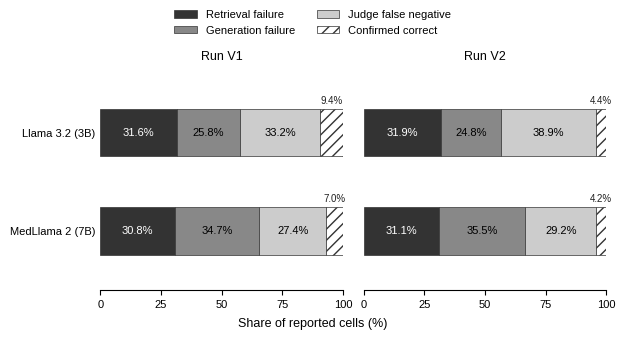

In [10]:
diagnosis_styles = {
    "retrieval_miss": ("#333333", "", "white"),
    "generation_miss": ("#888888", "", "black"),
    "judge_false_negative": ("#cccccc", "", "black"),
    "confirmed_correct": ("white", "///", "black"),
    "unresolved": ("white", "xx", "black"),
}
shown_diagnoses = [key for key in DIAGNOSIS_LABELS if accuracy[key].sum() > 0]
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 3.3), sharex=True, sharey=True, layout="constrained")
    for ax, version in zip(axes, VERSIONS):
        records = accuracy.loc[version].reindex(MODELS)
        left = np.zeros(len(MODELS))
        for diagnosis in shown_diagnoses:
            percentages = records[diagnosis].to_numpy(dtype=float) / records["n_cells"].to_numpy() * 100
            color, hatch, text_color = diagnosis_styles[diagnosis]
            ax.barh(np.arange(len(MODELS)), percentages, left=left, height=0.48, color=color, hatch=hatch,
                    edgecolor="#333333", linewidth=0.5, label=DIAGNOSIS_LABELS[diagnosis])
            for row, percentage in enumerate(percentages):
                if percentage >= 10:
                    ax.text(left[row] + percentage / 2, row, f"{percentage:.1f}%",
                            ha="center", va="center", fontsize=8, color=text_color)
                elif percentage >= 1:
                    # Too narrow for an inside label: annotate just above the segment.
                    ax.text(left[row] + percentage / 2, row - 0.28, f"{percentage:.1f}%",
                            ha="center", va="bottom", fontsize=7, color="#202020")
            left += percentages
        ax.set_title(f"Run {version}", fontsize=9, pad=10)
        ax.set_yticks(np.arange(len(MODELS)), [MODEL_LABELS[model] for model in MODELS])
        ax.set_ylim(len(MODELS) - 0.4, -0.6)
        ax.set_xlim(0, 100)
        ax.set_xticks([0, 25, 50, 75, 100])
        ax.tick_params(axis="y", length=0)
        ax.spines[["top", "right", "left"]].set_visible(False)
    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="outside upper center", ncol=2, frameon=False, fontsize=8)
    fig.supxlabel("Share of reported cells (%)", fontsize=9)
    save_figure(fig, S4_DIR, "01_diagnosis_outcomes")

**Run-to-run stability.** V1 and V2 regenerate the answers from the same
retrieved contexts, so comparing them shows how stable extraction is across
repeated generation. **Table:** for each model, reported cells that are correct
in both runs, in only one run, or in neither (resolved cells in both runs only).

In [11]:
stability_records = []
for model in MODELS:
    paired = (
        reviewed.loc[reviewed["model"].eq(model) & reviewed["resolved"]]
        .pivot(index=REFERENCE_KEYS, columns="version", values="human_correct")
        .dropna()
        .astype(bool)
    )
    v1, v2 = paired[VERSIONS[0]], paired[VERSIONS[1]]
    stability_records.append({
        "model": model, "paired_cells": len(paired),
        "correct_both": int((v1 & v2).sum()), f"correct_only_{VERSIONS[0]}": int((v1 & ~v2).sum()),
        f"correct_only_{VERSIONS[1]}": int((~v1 & v2).sum()), "correct_neither": int((~v1 & ~v2).sum()),
        "same_outcome_rate": (v1 == v2).mean(),
    })
stability = pd.DataFrame(stability_records).set_index("model")
stability.to_csv(S4_DIR / "run_to_run_stability.csv")
display(stability.round(3))

,paired_cells,correct_both,correct_only_V1,correct_only_V2,correct_neither,same_outcome_rate
model,,,,,,
Llama,383,141,22,25,195,0.877
MedLlama,383,83,49,45,206,0.755


## 5. Per-field accuracy

**Figure caption:** Retrieval failures, generation failures, and correct answers
(`confirmed_correct` + `judge_false_negative`) for each broad field. Rates use
resolved reported cells within each field and run, so the three rates sum to
100%. Row labels give the number of reported cells per run. Darker cells indicate
a larger share of the named outcome: lower is preferable for failure rates,
higher for correctness.

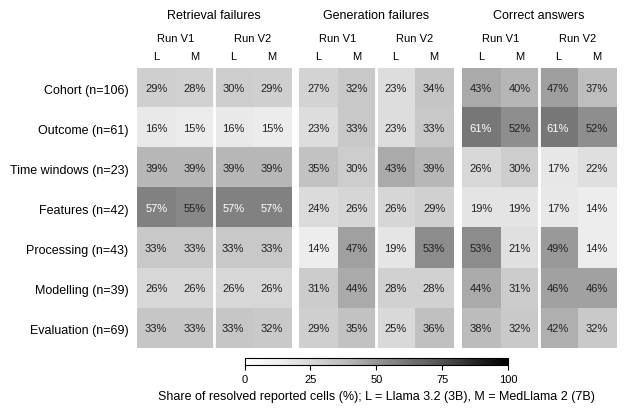

In [12]:
S5_DIR = section_dir("5_per_field")
field_summaries = {}
for level in ["field_id", "category"]:
    field_summaries[level] = pd.DataFrame([
        {"version": version, "model": model, level: key, **summarize_diagnoses(group)}
        for (version, model, key), group in reviewed.groupby(["version", "model", level], sort=False)
    ])
    field_summaries[level].to_csv(S5_DIR / f"accuracy_by_{level}.csv", index=False)

reported_support = dataset.loc[dataset["status"].eq("reported")]
field_labels = [
    f"{FIELD_LABELS.get(field, field)} (n={count})"
    for field, count in reported_support.groupby("field_id").size().reindex(field_order).items()
]

def draw_rate_heatmap(ax, summary, level, rows, rate, label_size):
    table = summary.pivot(index=level, columns=["version", "model"], values=rate).reindex(index=rows, columns=RUN_INDEX)
    values = table.to_numpy(dtype=float)
    image = ax.imshow(np.ma.masked_invalid(values), cmap="Greys", vmin=0, vmax=1, aspect="auto")
    for y in range(len(rows)):
        for x in range(len(RUN_INDEX)):
            value = values[y, x]
            ax.text(x, y, f"{value:.0%}" if np.isfinite(value) else "N/A", ha="center", va="center",
                    fontsize=label_size, color="white" if value > 0.55 else "#202020")
    ax.set_xticks(np.arange(len(RUN_INDEX)), ["L", "M", "L", "M"])
    ax.xaxis.tick_top()
    ax.tick_params(axis="x", length=0, labelsize=8, pad=5)
    run_axis = ax.secondary_xaxis("top")
    run_axis.set_xticks([0.5, 2.5], [f"Run {version}" for version in VERSIONS])
    run_axis.tick_params(length=0, labelsize=8, pad=18)
    run_axis.spines["top"].set_visible(False)
    ax.tick_params(axis="y", length=0, pad=6)
    ax.axvline(1.5, color="white", linewidth=2)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return image

rate_panels = {
    "retrieval_failure_rate": "Retrieval failures",
    "generation_failure_rate": "Generation failures",
    "correct_rate": "Correct answers",
}
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(TEXT_WIDTH, 4.0), sharey=True, layout="constrained")
    for ax, (rate, title) in zip(axes, rate_panels.items()):
        image = draw_rate_heatmap(ax, field_summaries["field_id"], "field_id", field_order, rate, 8)
        ax.set_title(title, fontsize=9, pad=36)
    axes[0].set_yticks(np.arange(len(field_order)), field_labels, fontsize=9)
    colorbar = fig.colorbar(image, ax=axes, location="bottom", shrink=0.55, aspect=40, pad=0.03)
    colorbar.set_ticks([0, 0.25, 0.5, 0.75, 1], labels=["0", "25", "50", "75", "100"])
    colorbar.set_label("Share of resolved reported cells (%); L = Llama 3.2 (3B), M = MedLlama 2 (7B)", fontsize=9)
    save_figure(fig, S5_DIR, "01_accuracy_by_field")

**Figure caption (appendix candidate):** Share of correct answers for all 38
extraction questions, in canonical question order. Row labels give the number of
reported cells per run; questions reported in few papers support weaker
conclusions than those reported in all twelve.

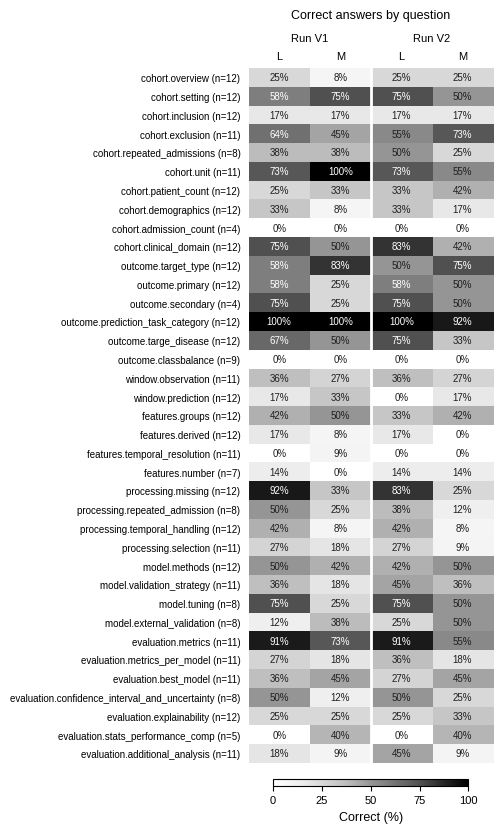

In [13]:
question_support = reported_support.groupby("category").size().reindex(query_order)
# Questions without reported cells (all papers not reported) have no accuracy to show.
plot_order = [category for category in query_order if question_support.get(category, 0) > 0]
question_labels = [f"{category} (n={int(question_support[category])})" for category in plot_order]
with plt.rc_context(PLOT_STYLE):
    fig, ax = plt.subplots(figsize=(TEXT_WIDTH * 0.8, 8.2), layout="constrained")
    image = draw_rate_heatmap(ax, field_summaries["category"], "category", plot_order, "correct_rate", 7)
    ax.set_yticks(np.arange(len(plot_order)), question_labels, fontsize=7)
    ax.set_title("Correct answers by question", fontsize=9, pad=36)
    colorbar = fig.colorbar(image, ax=ax, location="bottom", shrink=0.8, aspect=30, pad=0.02)
    colorbar.set_ticks([0, 0.25, 0.5, 0.75, 1], labels=["0", "25", "50", "75", "100"])
    colorbar.set_label("Correct (%)", fontsize=9)
    save_figure(fig, S5_DIR, "02_correct_by_question")

question_table = (
    field_summaries["category"].pivot(index="category", columns=["version", "model"], values="correct_rate")
    .reindex(index=query_order, columns=RUN_INDEX)
)
question_table.insert(0, "reported_cells", question_support)
question_table.insert(0, "field", question_table.index.map(query_catalog.set_index("category")["field_id"]).map(FIELD_LABELS))
question_table.to_csv(S5_DIR / "correct_rate_by_question.csv")

## 6. Automated vs manual evaluation

Bulk extraction produces far more cells than can be reviewed by hand, so the
question is whether RAGAS can stand in for manual review. Each judge is compared
with the manual diagnosis on its own run. The manual labels give two separate
verdicts:

| Human diagnosis | Human answer verdict | Human context verdict |
| --- | --- | --- |
| `retrieval_miss` | Failure | Context lacks the answer |
| `generation_miss` | Failure | Context contains the answer |
| `judge_false_negative`, `confirmed_correct` | Correct | Not assessed |

With a correct answer as the positive class, a **judge false negative** is a
correct answer the judge flagged and a **judge false positive** is a failure the
judge marked `ok`. Separation is summarized with the AUC: the probability that
a randomly chosen good case scores higher than a randomly chosen bad one
(0.5 = chance, 1.0 = perfect).

Because V1 and V2 differ in both judge and generated answers, judge differences
are read through their agreement with the manual labels, not by comparing scores
directly.

In [14]:
S6_DIR = section_dir("6_automated_vs_manual")
CALIBRATION_EDGES = np.linspace(0, 1, 11)
MIN_BIN_SIZE = 5

def compare_with_judge(diagnosis, failure_category):
    judge = clean_label(failure_category)
    if diagnosis == "unresolved" or judge not in JUDGE_FLAGGED | {"ok"}:
        return "not_comparable"
    human_correct, judge_correct = diagnosis in CORRECT_DIAGNOSES, judge == "ok"
    return {
        (True, True): "agree_correct", (False, False): "agree_failure",
        (True, False): "judge_false_negative", (False, True): "judge_false_positive",
    }[(human_correct, judge_correct)]

reviewed["comparison"] = [
    compare_with_judge(diagnosis, judge) for diagnosis, judge in zip(reviewed["diagnosis"], reviewed["failure_category"])
]
resolved_rows = reviewed.loc[reviewed["resolved"]]

agreement_records, calibration_records = [], []
for (version, model), group in resolved_rows.groupby(["version", "model"], sort=False):
    comparisons = group["comparison"].value_counts()
    agree_correct, agree_failure, judge_fn, judge_fp = (
        int(comparisons.get(key, 0))
        for key in ["agree_correct", "agree_failure", "judge_false_negative", "judge_false_positive"]
    )
    human_correct = group["diagnosis"].isin(CORRECT_DIAGNOSES)
    is_generation = group["diagnosis"].eq("generation_miss")
    is_retrieval = group["diagnosis"].eq("retrieval_miss")
    agreement_records.append({
        "version": version, "judge_model": JUDGE_MODELS[version], "model": model,
        "agree_correct": agree_correct, "agree_failure": agree_failure,
        "judge_false_negative": judge_fn, "judge_false_positive": judge_fp,
        "judge_accuracy": safe_rate(agree_correct + agree_failure, agree_correct + agree_failure + judge_fn + judge_fp),
        "judge_false_negative_rate": safe_rate(judge_fn, agree_correct + judge_fn),
        "judge_false_positive_rate": safe_rate(judge_fp, agree_failure + judge_fp),
        "median_ac_correct": group.loc[human_correct, "answer_correctness"].median(),
        "median_ac_failure": group.loc[~human_correct, "answer_correctness"].median(),
        "share_correct_above_threshold": group.loc[human_correct, "answer_correctness"].ge(CORRECTNESS_THRESHOLD).mean(),
        "answer_correctness_auc": separation_auc(
            group.loc[human_correct, "answer_correctness"], group.loc[~human_correct, "answer_correctness"]
        ),
        "median_cr_generation_miss": group.loc[is_generation, "context_recall"].median(),
        "median_cr_retrieval_miss": group.loc[is_retrieval, "context_recall"].median(),
        "context_recall_auc": separation_auc(
            group.loc[is_generation, "context_recall"], group.loc[is_retrieval, "context_recall"]
        ),
    })
    scored = group.dropna(subset=["answer_correctness"])
    bins = np.clip(np.digitize(scored["answer_correctness"], CALIBRATION_EDGES[1:-1]), 0, len(CALIBRATION_EDGES) - 2)
    for index, bin_rows in scored.groupby(bins):
        n, correct = len(bin_rows), int(bin_rows["diagnosis"].isin(CORRECT_DIAGNOSES).sum())
        low, high = wilson_interval(correct, n)
        calibration_records.append({
            "version": version, "model": model,
            "bin_low": CALIBRATION_EDGES[index], "bin_high": CALIBRATION_EDGES[index + 1],
            "mean_answer_correctness": bin_rows["answer_correctness"].mean(),
            "n": n, "human_correct_n": correct, "human_correct_rate": correct / n, "ci_low": low, "ci_high": high,
        })

judge_agreement = pd.DataFrame(agreement_records).set_index(["version", "model"]).reindex(RUN_INDEX)
calibration = pd.DataFrame(calibration_records)
judge_agreement.to_csv(S6_DIR / "judge_vs_manual.csv")
calibration.to_csv(S6_DIR / "answer_correctness_calibration.csv", index=False)
reviewed.loc[reviewed["comparison"].isin(["judge_false_negative", "judge_false_positive"])].drop(
    columns=["response"], errors="ignore"
).to_csv(S6_DIR / "judge_manual_disagreements.csv", index=False)
display(judge_agreement[[
    "judge_model", "agree_correct", "agree_failure", "judge_false_negative", "judge_false_positive",
    "judge_accuracy", "judge_false_negative_rate", "judge_false_positive_rate",
]].round(3))

judge_model  agree_correct  agree_failure  \
version model                                                       
V1      Llama          gpt-5.6-luna             36            218   
        MedLlama       gpt-5.6-luna             27            250   
V2      Llama     ministral-8b-2512             17            214   
        MedLlama  ministral-8b-2512             16            252   

                  judge_false_negative  judge_false_positive  judge_accuracy  \
version model                                                                  
V1      Llama                      127                     2           0.663   
        MedLlama                   105                     1           0.723   
V2      Llama                      149                     3           0.603   
        MedLlama                   112                     3           0.700   

                  judge_false_negative_rate  judge_false_positive_rate  
version model                                                           
V1      Llama                         0.779                      0.009  
        MedLlama                      0.795                      0.004  
V2      Llama                         0.898                      0.014  
        MedLlama                      0.875                      0.012

**Figure caption:** Share of reported cells diagnosed as correct by the human
reviewer within bins of RAGAS answer correctness (width 0.1), per judge. Points
sit at the mean score of each bin; error bars are 95% Wilson intervals. Bins with
fewer than five cells are omitted (all bins are in the exported CSV). The dotted
diagonal marks a score equal to the human-correct rate; the dashed vertical line
is the 0.75 correctness threshold. The legend gives the AUC for separating
human-correct from human-failed answers.

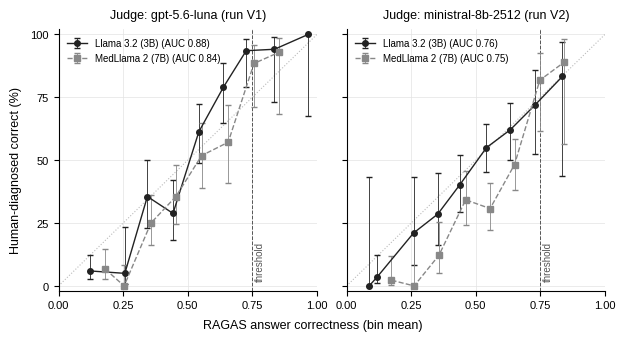

In [15]:
calibration_styles = {
    "Llama": {"color": "#222222", "marker": "o", "linestyle": "-", "offset": -0.008},
    "MedLlama": {"color": "#888888", "marker": "s", "linestyle": "--", "offset": 0.008},
}
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 3.3), sharex=True, sharey=True, layout="constrained")
    for ax, version in zip(axes, VERSIONS):
        ax.plot([0, 1], [0, 1], color="#bbbbbb", linestyle=":", linewidth=0.8)
        ax.axvline(CORRECTNESS_THRESHOLD, color="#555555", linestyle="--", linewidth=0.7)
        for model in MODELS:
            style = calibration_styles[model]
            points = calibration.loc[
                calibration["version"].eq(version) & calibration["model"].eq(model) & calibration["n"].ge(MIN_BIN_SIZE)
            ]
            x = points["mean_answer_correctness"] + style["offset"]
            y = points["human_correct_rate"]
            auc = judge_agreement.loc[(version, model), "answer_correctness_auc"]
            ax.errorbar(x, y, yerr=[y - points["ci_low"], points["ci_high"] - y],
                        color=style["color"], marker=style["marker"], linestyle=style["linestyle"],
                        markersize=4, linewidth=1, elinewidth=0.6, capsize=2,
                        label=f"{MODEL_LABELS[model]} (AUC {auc:.2f})")
        ax.text(CORRECTNESS_THRESHOLD + 0.01, 0.02, "threshold", fontsize=7, color="#555555", rotation=90, va="bottom")
        ax.set_title(f"Judge: {JUDGE_MODELS[version]} (run {version})", fontsize=9, pad=8)
        ax.set_xlim(0, 1)
        ax.set_ylim(-0.02, 1.02)
        ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
        ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0", "25", "50", "75", "100"])
        ax.grid(color="#e3e3e3", linewidth=0.5)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(loc="upper left", frameon=False, fontsize=7)
    fig.supxlabel("RAGAS answer correctness (bin mean)", fontsize=9)
    fig.supylabel("Human-diagnosed correct (%)", fontsize=9)
    save_figure(fig, S6_DIR, "01_answer_correctness_vs_manual")

**Figure caption:** RAGAS context recall for human-diagnosed failures, split by
whether the retrieved context contained the answer (`generation_miss`) or lacked
it (`retrieval_miss`). Boxes show the median and interquartile range; points are
individual cells with horizontal jitter. The AUC is the probability that a
generation miss receives higher context recall than a retrieval miss.
Human-correct answers are excluded because correctness does not establish
whether the context contained the answer.

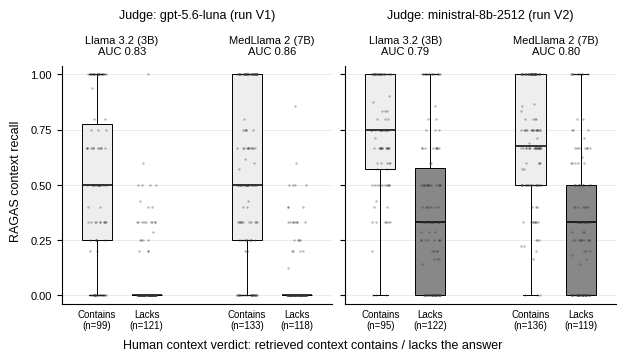

In [16]:
context_groups = [("generation_miss", "Contains"), ("retrieval_miss", "Lacks")]
context_colors = {"generation_miss": "#eeeeee", "retrieval_miss": "#888888"}
jitter = np.random.default_rng(2026)
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 3.5), sharey=True, layout="constrained")
    for ax, version in zip(axes, VERSIONS):
        tick_positions, tick_labels = [], []
        for model_index, model in enumerate(MODELS):
            rows = resolved_rows.loc[resolved_rows["version"].eq(version) & resolved_rows["model"].eq(model)]
            positions = [model_index * 3 + 1, model_index * 3 + 2]
            values = [rows.loc[rows["diagnosis"].eq(diagnosis), "context_recall"].dropna().to_numpy()
                      for diagnosis, _ in context_groups]
            boxes = ax.boxplot(values, positions=positions, widths=0.6, patch_artist=True, showfliers=False,
                               medianprops={"color": "black", "linewidth": 1.1}, boxprops={"linewidth": 0.7},
                               whiskerprops={"linewidth": 0.7}, capprops={"linewidth": 0.7})
            for box, (diagnosis, _) in zip(boxes["boxes"], context_groups):
                box.set_facecolor(context_colors[diagnosis])
            for position, scores in zip(positions, values):
                ax.scatter(position + jitter.uniform(-0.2, 0.2, len(scores)), scores, s=3,
                           color="#333333", alpha=0.35, linewidths=0, zorder=3)
            auc = judge_agreement.loc[(version, model), "context_recall_auc"]
            ax.text(np.mean(positions), 1.08, f"{MODEL_LABELS[model]}\nAUC {auc:.2f}", ha="center", va="bottom", fontsize=8)
            tick_positions += positions
            tick_labels += [f"{label}\n(n={len(scores)})" for (_, label), scores in zip(context_groups, values)]
        ax.set_xticks(tick_positions, tick_labels, fontsize=7)
        ax.set_xlim(0.3, 5.7)
        ax.set_ylim(-0.04, 1.04)
        ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
        ax.set_title(f"Judge: {JUDGE_MODELS[version]} (run {version})", fontsize=9, pad=34)
        ax.tick_params(axis="x", length=0)
        ax.grid(axis="y", color="#e3e3e3", linewidth=0.5)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
    fig.supxlabel("Human context verdict: retrieved context contains / lacks the answer", fontsize=9)
    fig.supylabel("RAGAS context recall", fontsize=9)
    save_figure(fig, S6_DIR, "02_context_recall_vs_manual")

In [17]:
story = ["### What the comparison shows", ""]
for version in VERSIONS:
    for model in MODELS:
        record = judge_agreement.loc[(version, model)]
        story.append(
            f"- **{JUDGE_MODELS[version]} / {MODEL_LABELS[model]}:** judge accuracy {record.judge_accuracy:.1%}; "
            f"it flagged {record.judge_false_negative_rate:.1%} of correct answers and passed "
            f"{record.judge_false_positive_rate:.1%} of failures. Answer correctness AUC "
            f"{record.answer_correctness_auc:.2f}; only {record.share_correct_above_threshold:.1%} of correct answers "
            f"reach {CORRECTNESS_THRESHOLD}. Context recall AUC {record.context_recall_auc:.2f}."
        )
story += [
    "",
    "**Interpretation:** AUC measures ranking agreement with the manual diagnosis, independent of any threshold. "
    "The share of correct answers reaching the threshold shows how much of the judge's flagging comes from the "
    "threshold rather than from the ranking. Context results cover human-diagnosed failures only.",
]
story_text = "\n".join(story)
display(Markdown(story_text))
_ = (S6_DIR / "interpretation.md").write_text(story_text + "\n", encoding="utf-8")

### What the comparison shows

- **gpt-5.6-luna / Llama 3.2 (3B):** judge accuracy 66.3%; it flagged 77.9% of correct answers and passed 0.9% of failures. Answer correctness AUC 0.88; only 22.1% of correct answers reach 0.75. Context recall AUC 0.83.
- **gpt-5.6-luna / MedLlama 2 (7B):** judge accuracy 72.3%; it flagged 79.5% of correct answers and passed 0.4% of failures. Answer correctness AUC 0.84; only 20.5% of correct answers reach 0.75. Context recall AUC 0.86.
- **ministral-8b-2512 / Llama 3.2 (3B):** judge accuracy 60.3%; it flagged 89.8% of correct answers and passed 1.4% of failures. Answer correctness AUC 0.76; only 10.2% of correct answers reach 0.75. Context recall AUC 0.79.
- **ministral-8b-2512 / MedLlama 2 (7B):** judge accuracy 70.0%; it flagged 87.5% of correct answers and passed 1.2% of failures. Answer correctness AUC 0.75; only 12.5% of correct answers reach 0.75. Context recall AUC 0.80.

**Interpretation:** AUC measures ranking agreement with the manual diagnosis, independent of any threshold. The share of correct answers reaching the threshold shows how much of the judge's flagging comes from the threshold rather than from the ranking. Context results cover human-diagnosed failures only.

## 7. Summary of key results

One row per run and response model, collecting the headline numbers from
Sections 2–6. Llama 3.2 (3B) is a general-purpose model and MedLlama 2 (7B) a
medical fine-tune of Llama 2; they also differ in model generation, size and
native context window, so differences between them cannot be attributed to
domain adaptation alone.

In [18]:
S7_DIR = section_dir("7_summary")
key_results = pd.DataFrame({
    "model type": [MODEL_TYPES[model] for _, model in RUN_INDEX],
    "paper coverage": completeness["paper_coverage"],
    "status sensitivity": status_metrics["sensitivity"],
    "status specificity": status_metrics["specificity"],
    "correct (reported cells)": accuracy["correct_rate"],
    "retrieval failures": accuracy["retrieval_failure_rate"],
    "generation failures": accuracy["generation_failure_rate"],
    "cell accuracy (all cells)": accuracy["cell_accuracy_all"],
    "judge": [JUDGE_MODELS[version] for version, _ in RUN_INDEX],
    "judge accuracy": judge_agreement["judge_accuracy"],
    "answer correctness AUC": judge_agreement["answer_correctness_auc"],
}, index=RUN_INDEX)
key_results.to_csv(S7_DIR / "key_results.csv")
percent_columns = [column for column in key_results.columns if column not in {"model type", "judge", "answer correctness AUC"}]
display(key_results.style.format({**{column: "{:.1%}" for column in percent_columns}, "answer correctness AUC": "{:.2f}"}))

## Appendix A. RAGAS score summaries (reported cells)

Mean RAGAS scores per run with exploratory 95% bootstrap intervals from 5,000
whole-paper resamples (12 papers, fixed seed). These are automated scores, not
observed accuracy (see Section 6). Because V1 and V2 differ in both judge and
generated answers, differences between runs are not a judge-only comparison.

version                V1              V2         
model               Llama MedLlama  Llama MedLlama
metric                                            
Faithfulness        0.715    0.607  0.746    0.677
Answer relevancy    0.456    0.614  0.408    0.527
Context recall      0.396    0.401  0.633    0.623
Context precision   0.762    0.773  0.815    0.817
Answer correctness  0.431    0.424  0.469    0.495

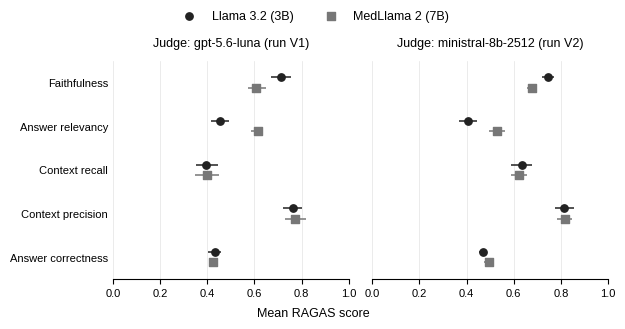

In [19]:
SA_DIR = section_dir("appendix_ragas")
ragas_long = reviewed.melt(
    id_vars=PAIR_KEYS + ["version", "model"], value_vars=list(RAGAS_METRICS), var_name="metric", value_name="score",
)
paper_ids = sorted(reviewed["article_id"].unique())
# Resample whole papers so questions from one paper stay together.
bootstrap_papers = np.random.default_rng(2026).integers(0, len(paper_ids), size=(5000, len(paper_ids)))

def summarize_scores(group):
    valid = group["score"].dropna()
    paper_stats = group.groupby("article_id")["score"].agg(["sum", "count"]).reindex(paper_ids, fill_value=0)
    sums = paper_stats["sum"].to_numpy()[bootstrap_papers].sum(axis=1)
    counts = paper_stats["count"].to_numpy()[bootstrap_papers].sum(axis=1)
    means = np.divide(sums, counts, out=np.full(sums.shape, np.nan), where=counts > 0)
    low, high = np.nanquantile(means, [0.025, 0.975])
    return {"n_valid": len(valid), "n_missing": int(group["score"].isna().sum()), "mean": valid.mean(),
            "median": valid.median(), "ci_low": low, "ci_high": high}

ragas_summary = pd.DataFrame([
    {"version": version, "model": model, "metric": metric, **summarize_scores(group)}
    for (version, model, metric), group in ragas_long.groupby(["version", "model", "metric"], sort=False)
])
ragas_summary.to_csv(SA_DIR / "ragas_summary.csv", index=False)
display(
    ragas_summary.pivot(index="metric", columns=["version", "model"], values="mean")
    .reindex(index=list(RAGAS_METRICS), columns=RUN_INDEX).rename(index=RAGAS_METRICS).round(3)
)

model_styles = {"Llama": {"color": "#222222", "marker": "o", "offset": -0.12},
                "MedLlama": {"color": "#777777", "marker": "s", "offset": 0.12}}
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 3.2), sharex=True, sharey=True, layout="constrained")
    for ax, version in zip(axes, VERSIONS):
        for model in MODELS:
            records = (ragas_summary.loc[ragas_summary["version"].eq(version) & ragas_summary["model"].eq(model)]
                       .set_index("metric").reindex(RAGAS_METRICS))
            style = model_styles[model]
            positions = np.arange(len(RAGAS_METRICS)) + style["offset"]
            ax.hlines(positions, records["ci_low"], records["ci_high"], color=style["color"], linewidth=1.1)
            ax.scatter(records["mean"], positions, color=style["color"], marker=style["marker"], s=28,
                       label=MODEL_LABELS[model], zorder=3)
        ax.set_title(f"Judge: {JUDGE_MODELS[version]} (run {version})", pad=10)
        ax.set_xlim(0, 1)
        ax.set_yticks(np.arange(len(RAGAS_METRICS)), list(RAGAS_METRICS.values()))
        ax.set_ylim(len(RAGAS_METRICS) - 0.5, -0.5)
        ax.grid(axis="x", color="#e3e3e3", linewidth=0.5)
        ax.set_axisbelow(True)
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.tick_params(axis="y", length=0)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=2, frameon=False, fontsize=9)
    fig.supxlabel("Mean RAGAS score", fontsize=9)
    save_figure(fig, SA_DIR, "01_ragas_mean_scores")

**Figure caption:** Distributions of reported-cell RAGAS scores per metric
(L = Llama 3.2 (3B), M = MedLlama 2 (7B)). Boxes span the interquartile range;
whiskers extend to 1.5 interquartile ranges; hollow circles are outliers.

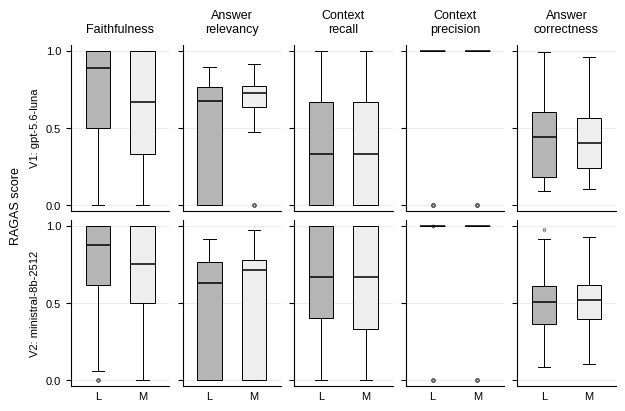

In [20]:
distribution_titles = ["Faithfulness", "Answer\nrelevancy", "Context\nrecall", "Context\nprecision", "Answer\ncorrectness"]
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(2, 5, figsize=(TEXT_WIDTH, 4.0), sharex=True, sharey=True, layout="constrained")
    for row, version in enumerate(VERSIONS):
        for column, (metric, title) in enumerate(zip(RAGAS_METRICS, distribution_titles)):
            ax = axes[row, column]
            values = [reviewed.loc[reviewed["version"].eq(version) & reviewed["model"].eq(model), metric].dropna().to_numpy()
                      for model in MODELS]
            boxes = ax.boxplot(values, positions=[1, 2], widths=0.55, patch_artist=True,
                               medianprops={"color": "black", "linewidth": 1.1}, boxprops={"linewidth": 0.7},
                               whiskerprops={"linewidth": 0.7}, capprops={"linewidth": 0.7},
                               flierprops={"marker": "o", "markersize": 2, "markerfacecolor": "none",
                                           "markeredgecolor": "#666666", "markeredgewidth": 0.4})
            for box, color in zip(boxes["boxes"], ["#b5b5b5", "#eeeeee"]):
                box.set_facecolor(color)
            ax.set_xticks([1, 2], ["L", "M"])
            ax.set_xlim(0.4, 2.6)
            ax.set_ylim(-0.04, 1.04)
            ax.set_yticks([0, 0.5, 1])
            ax.tick_params(axis="x", length=0, labelbottom=row == len(VERSIONS) - 1)
            ax.spines[["top", "right"]].set_visible(False)
            ax.grid(axis="y", color="#e3e3e3", linewidth=0.5)
            ax.set_axisbelow(True)
            if row == 0:
                ax.set_title(title, fontsize=9, pad=9)
            if column == 0:
                ax.set_ylabel(f"{version}: {JUDGE_MODELS[version]}", fontsize=8)
    fig.supylabel("RAGAS score", fontsize=9)
    save_figure(fig, SA_DIR, "02_ragas_score_distributions")

## Appendix B. RAGAS retrieval scores by field

**Figure caption:** Mean RAGAS context recall and context precision
(`llm_context_precision_with_reference`) per broad field and run. Both metrics
use the question, reference and retrieved contexts, not the generated answer.
Compare with the human-diagnosed retrieval failures in Section 5.

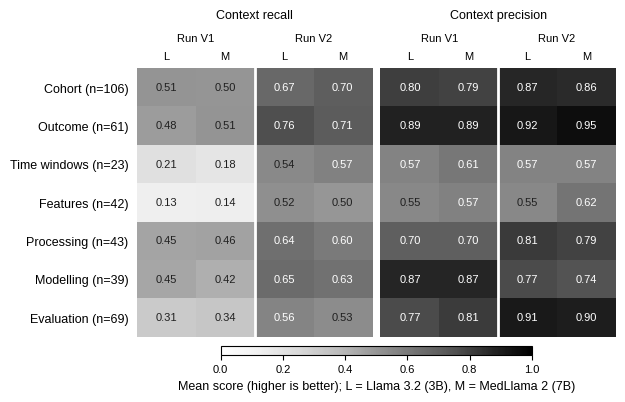

In [21]:
retrieval_metrics = {"context_recall": "Context recall", "llm_context_precision_with_reference": "Context precision"}
retrieval_by_field = (
    reviewed.groupby(["version", "model", "field_id"])[list(retrieval_metrics)].mean().reset_index()
)
retrieval_by_field.to_csv(SA_DIR / "retrieval_scores_by_field.csv", index=False)
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 3.9), sharey=True, layout="constrained")
    for ax, (metric, title) in zip(axes, retrieval_metrics.items()):
        image = draw_rate_heatmap(ax, retrieval_by_field, "field_id", field_order, metric, 8)
        for text in ax.texts:
            value = text.get_text()
            if value.endswith("%"):
                text.set_text(f"{float(value[:-1]) / 100:.2f}")
        ax.set_title(title, fontsize=9, pad=36)
    axes[0].set_yticks(np.arange(len(field_order)), field_labels, fontsize=9)
    colorbar = fig.colorbar(image, ax=axes, location="bottom", shrink=0.65, aspect=35, pad=0.03)
    colorbar.set_label("Mean score (higher is better); L = Llama 3.2 (3B), M = MedLlama 2 (7B)", fontsize=9)
    save_figure(fig, SA_DIR, "03_retrieval_scores_by_field")